In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm.auto import tqdm

In [3]:
import mctpy as mct

In [4]:
from mctpy.structurefactors.oz import PY, HSS

In [5]:
rho = 1.0

In [6]:
Sq = mct.structurefactors.oz.Sq()
_ = Sq.solve (closure=PY(), potential=HSS(), rho=rho, accuracy=1e-12, N=8192, use_ng=False)

In [7]:
Sq2 = mct.structurefactors.oz.Sq()
_ = Sq2.solve (closure=PY(), potential=HSS(), rho=rho, accuracy=1e-12, N=8192, use_ng=True)

In [8]:
qgrid = np.linspace(0.2,39.8,100)
hspy = mct.structurefactors.hssPY(phi=rho*np.pi/6.)

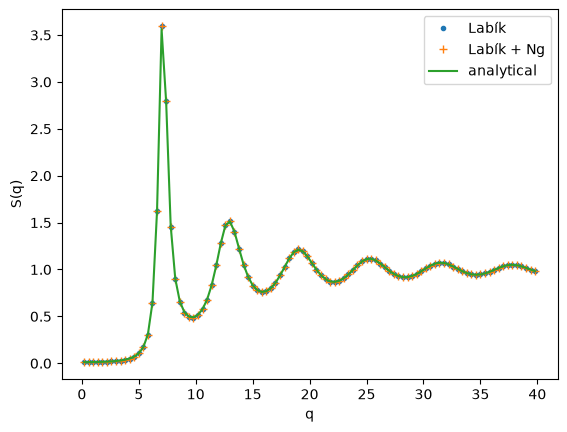

In [9]:
plt.plot(qgrid, Sq.Sq(qgrid)[0], '.', label='Labík')
plt.plot(qgrid, Sq.Sq(qgrid)[0], '+', label='Labík + Ng')
plt.plot(qgrid, hspy.Sq(qgrid)[0], label='analytical')
plt.xlabel('q')
plt.ylabel('S(q)')
plt.legend()
plt.show()

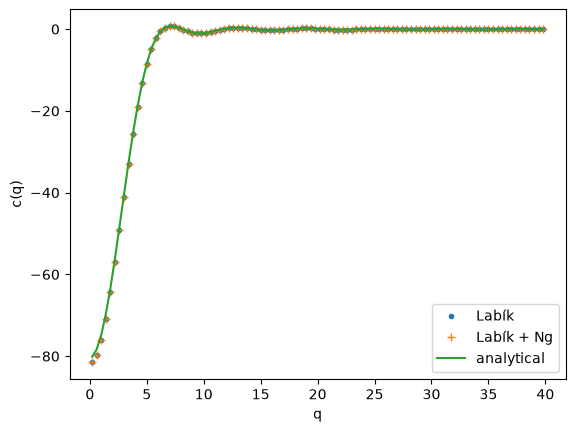

In [10]:
plt.plot(qgrid, Sq.Sq(qgrid)[1], '.', label='Labík')
plt.plot(qgrid, Sq.Sq(qgrid)[1], '+', label='Labík + Ng')
plt.plot(qgrid, hspy.Sq(qgrid)[1], label='analytical')
plt.xlabel('q')
plt.ylabel('c(q)')
plt.legend()
plt.show()

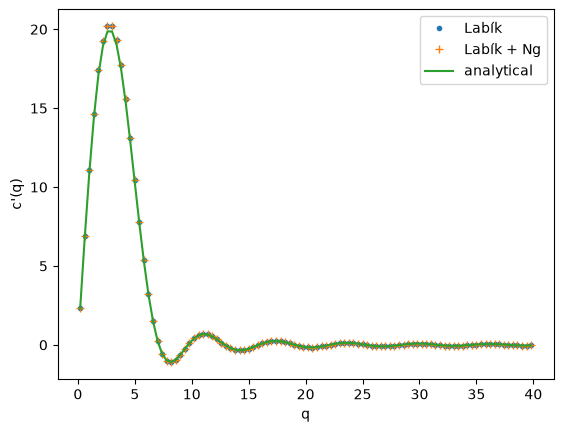

In [11]:
plt.plot(qgrid, Sq.dcq_dq(qgrid), '.', label='Labík')
plt.plot(qgrid, Sq.dcq_dq(qgrid), '+', label='Labík + Ng')
plt.plot(qgrid, hspy.dcq_dq(qgrid), label='analytical')
plt.xlabel('q')
plt.ylabel("c'(q)")
plt.legend()
plt.show()

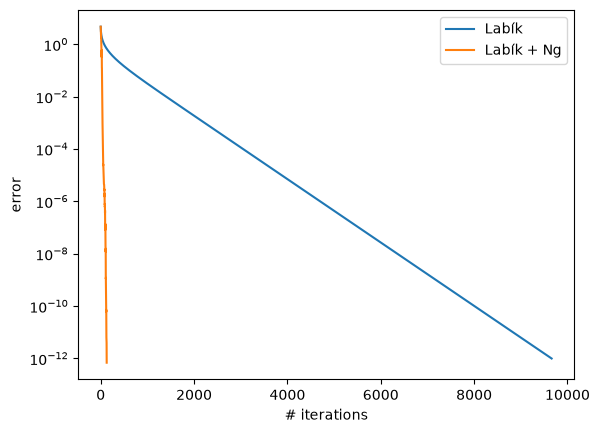

In [12]:
plt.plot(Sq.errlog, label='Labík')
plt.plot(Sq2.errlog, label='Labík + Ng')
plt.xlabel('# iterations')
plt.ylabel('error')
plt.yscale('log')
plt.legend()
plt.show()

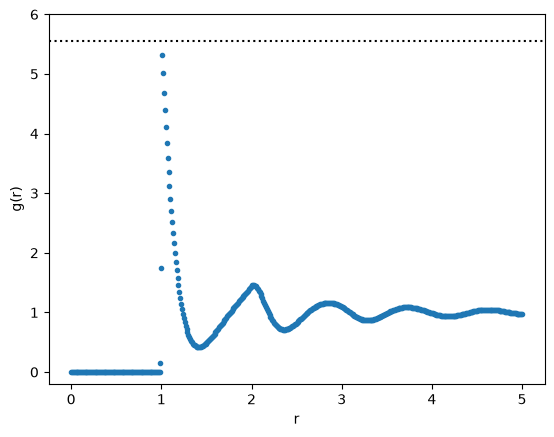

In [13]:
r = np.linspace(0,5,501)
phi = rho*np.pi/6.
plt.plot(r, Sq.gr(r),'.')
plt.axhline((1-1.5*phi+0.5*phi**3)/(1-phi)**4,linestyle='dotted',color='black')
plt.xlabel('r')
plt.ylabel('g(r)')
plt.ylim(-0.2,6)
plt.show()

In [14]:
from mctpy.structurefactors.oz import LJ, HNC

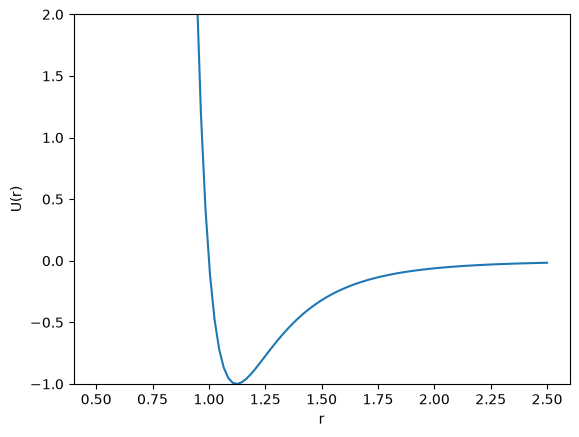

In [15]:
r = np.linspace(0.5,2.5,100)
plt.plot(r,LJ()(r))
plt.ylim(-1,2)
plt.xlabel('r')
plt.ylabel('U(r)')
plt.show()

In [16]:
Sq_LJ = mct.structurefactors.oz.Sq()
Gq0, Gr0 = None, None
for kT in tqdm([5.0,4.0,3.0,2.0,1.5,1.2]):
    Gr0, Gq0 = Sq_LJ.solve (closure=HNC(), potential=LJ(), rho=1.2, kT=kT, accuracy=1e-12, N=8192, use_ng=True, Gq0=Gq0, Gr0=Gr0)

  0%|          | 0/6 [00:00<?, ?it/s]

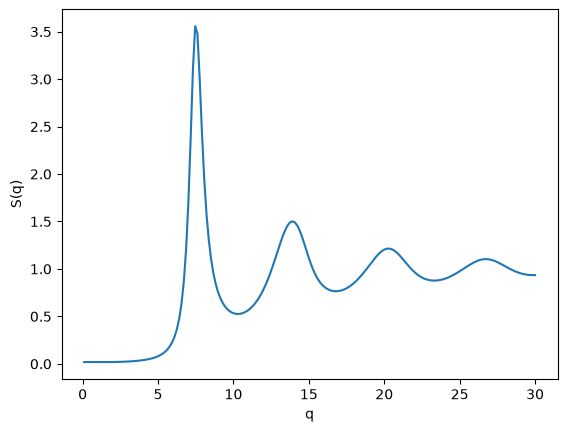

In [17]:
q = np.linspace(0.1,30,200)
plt.plot(q,Sq_LJ.Sq(q)[0])
plt.xlabel('q')
plt.ylabel('S(q)')
plt.show()

In [18]:
from mctpy.structurefactors.oz import PYmix, HSM

In [19]:
rho = [0.5, 0.1]
d = [1.0, 0.6]

In [20]:
Sq = mct.structurefactors.oz.mixtureSq()
_ = Sq.solve (closure=PYmix(), potential=HSM(sigma=d), rho=rho, use_ng=True)

In [21]:
hsmpy = mct.structurefactors.hsmPY(rho,d)
qgrid = np.linspace(0.2,39.8,100)

In [22]:
nsq, ncq = Sq.Sq(qgrid)
sq, cq = hsmpy.Sq(qgrid)

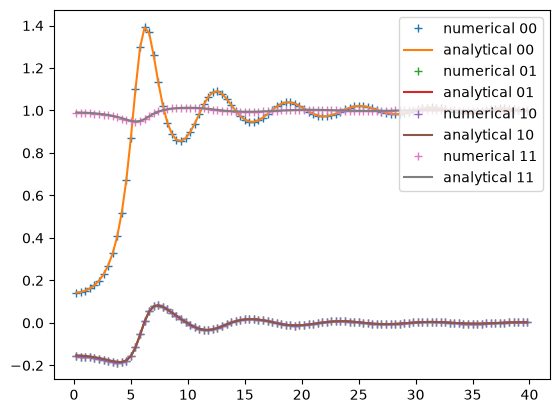

In [23]:
for i in range(2):
    for j in range(2):
        plt.plot(qgrid, nsq[:,i,j], '+', label=f'numerical {i}{j}')
        plt.plot(qgrid, sq[:,i,j], label=f'analytical {i}{j}')
plt.legend(loc=1)
plt.show()

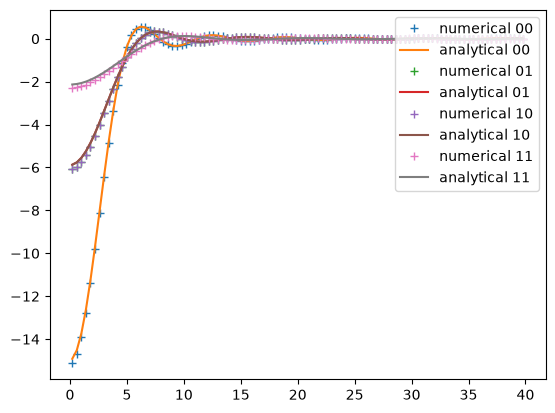

In [24]:
for i in range(2):
    for j in range(2):
        plt.plot(qgrid, ncq[:,i,j], '+', label=f'numerical {i}{j}')
        plt.plot(qgrid, cq[:,i,j], label=f'analytical {i}{j}')
plt.legend(loc=1)
plt.show()

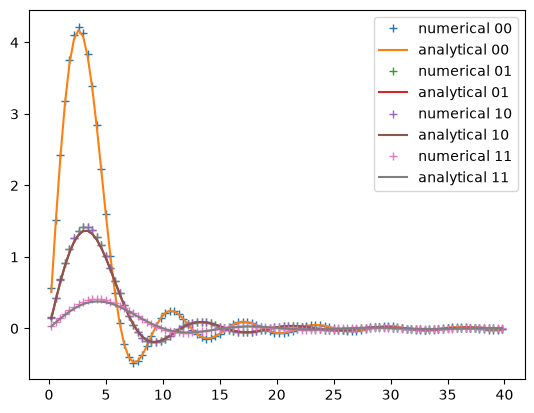

In [25]:
for i in range(2):
    for j in range(2):
        plt.plot(qgrid, Sq.dcq_dq(qgrid)[:,i,j], '+', label=f'numerical {i}{j}')
        plt.plot(qgrid, hsmpy.dcq_dq(qgrid)[:,i,j], label=f'analytical {i}{j}')
plt.legend(loc=1)
plt.show()

In [26]:
from mctpy.structurefactors.oz import LJmix, HNCmix

In [27]:
rho = np.array([0.963,0.241])
Tlist = np.array([5.0, 4.0, 3.0, 2.0, 1.5, 1.0])

In [28]:
sqlist = []
Gq0, Gr0 = None, None
for kT in tqdm(Tlist):
    Sq_KA = mct.structurefactors.oz.mixtureSq()
    Gr0, Gq0 = Sq_KA.solve (closure=HNCmix(), potential=LJmix(), rho=rho, kT=kT, use_ng=True, Gq0=Gq0, Gr0=Gr0)
    sqlist.append(Sq_KA)

  0%|          | 0/6 [00:00<?, ?it/s]

/scratch/tv/NOSYNC/CACHE/python-mct/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


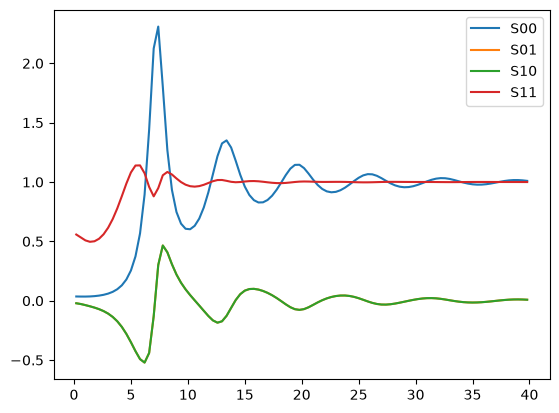

In [29]:
nsq, ncq = Sq_KA.Sq(qgrid)
for i in range(2):
    for j in range(2):
        plt.plot(qgrid, nsq[:,i,j], label=f'S{i}{j}')
plt.legend(loc=1)
plt.show()

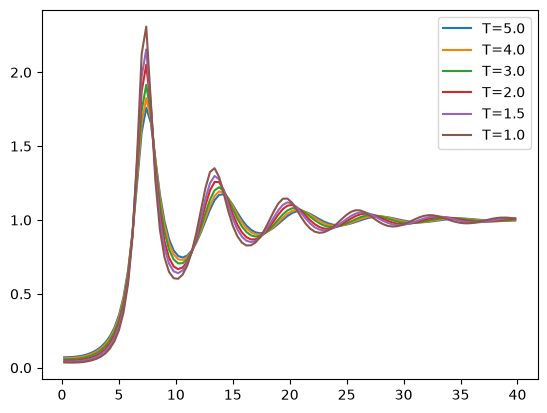

In [30]:
for ti, Sq in enumerate(sqlist):
    plt.plot(qgrid, Sq.Sq(qgrid)[0][:,0,0], label=f'T={Tlist[ti]}')
plt.legend()
plt.show()